Range: 84.0 251.0
Max difference vs OpenCV: 69


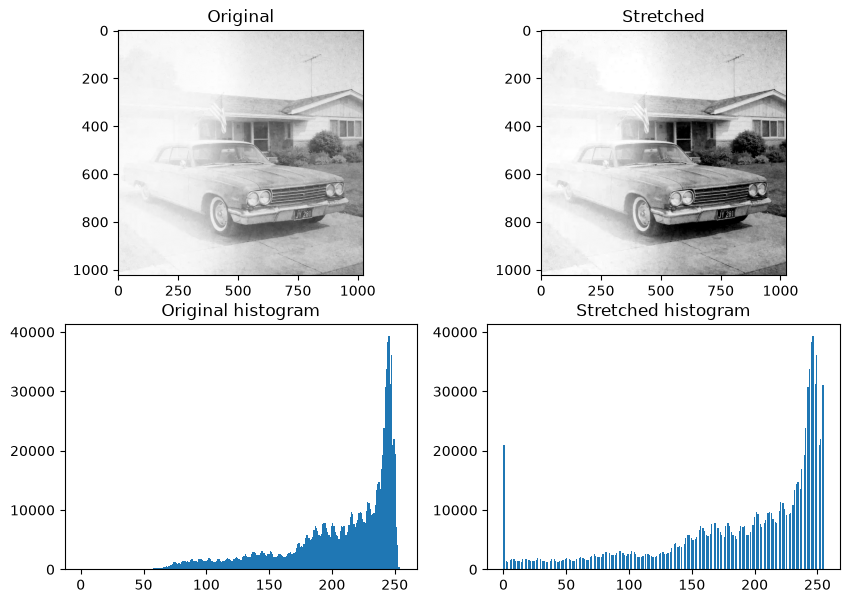

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("./images/old.png", 0)

rmin, rmax = np.percentile(img, (2, 98))
stretched = np.clip((img - rmin) / (rmax - rmin), 0, 1) * 255
print("Range:", rmin, rmax)

# convert to float BEFORE the math, then back to uint8
# stretched = (img.astype(np.float32) - rmin) / (rmax - rmin) * 255
stretched = np.round(stretched).astype(np.uint8)

ref = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)
print("Max difference vs OpenCV:", np.abs(stretched.astype(int) - ref.astype(int)).max())

plt.figure(figsize=(10, 7))
plt.subplot(2,2,1); plt.imshow(img, cmap="gray", vmin=0, vmax=255); plt.title("Original")
plt.subplot(2,2,2); plt.imshow(stretched, cmap="gray", vmin=0, vmax=255); plt.title("Stretched")
plt.subplot(2,2,3); plt.hist(img.ravel(), bins=256, range=(0,255)); plt.title("Original histogram")
plt.subplot(2,2,4); plt.hist(stretched.ravel(), bins=256, range=(0,255)); plt.title("Stretched histogram")
plt.show()